# Phase 2: ML v2 — Incorporating WAHIS Context
### Wildlife Health Anomaly Detection with Multi-Source Global Context

In this phase, we enrich our unsupervised anomaly detection pipeline by incorporating **macro-level global surveillance and population context** from official **WOAH/WAHIS (World Animal Health Information System)** exports.

#### Key Objectives & Architectural Rules:
1. **Respect Granularity Boundaries**: Do **NOT** force joins on mismatched levels (e.g. Kaggle does not record country or date; joins must occur only across genuine shared keys: **species category** across the modern WAHIS surveillance window).
2. **Derive Meaningful Context**: Extract global population scale, country surveillance breadth, premises density, and active surveillance tracking flags.
3. **Re-run Exact Unsupervised Pipeline**: Fit `IsolationForest` and `LocalOutlierFactor` (contamination=0.10) on the combined feature matrix $X_{v2}$ without ever exposing `Dangerous` labels to training.
4. **Side-by-Side Comparison**: Report v1 (Symptoms Only) vs. v2 (Symptoms + WAHIS Context) side-by-side across Confusion Matrices, Precision, Recall, and F1.


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline


C:\Users\Aditi Agarwal\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.sparse import csr_matrix, issparse


## 1. Multi-Source Data Ingestion
We load:
1. **Kaggle Clinical Dataset** (`data/raw/data.csv`): Micro-level individual animal records with 5 symptom slots.
2. **WAHIS Animal Population Export** (`data/raw/Animal population 2026-10-26.csv`): Macro-level country census and livestock premises counts by species category.
3. **WAHIS Six-Monthly Reports (SMR)** (`data/raw/SMR_2026-10-26_16-29.csv`): National semi-annual surveillance dossiers.
4. **WAHIS Annual Reports (AR)** (`data/raw/AR_2026-10-26.csv`): National annual surveillance dossiers.

In [2]:
df_kaggle = pd.read_csv("data/raw/data.csv")
df_pop = pd.read_csv("data/raw/Animal population 2026-10-26.csv")
df_smr = pd.read_csv("data/raw/SMR_2026-10-26_16-29.csv", sep=";")
df_ar = pd.read_csv("data/raw/AR_2026-10-26.csv", sep=";")

print(f"Kaggle Clinical Cases: {df_kaggle.shape[0]} rows, {df_kaggle.shape[1]} columns")
print(f"WAHIS Animal Population: {df_pop.shape[0]} rows, {df_pop.shape[1]} columns")
print(f"WAHIS SMR Reports: {df_smr.shape[0]} rows, {df_smr.shape[1]} columns")
print(f"WAHIS Annual Reports: {df_ar.shape[0]} rows, {df_ar.shape[1]} columns")


Kaggle Clinical Cases: 871 rows, 7 columns
WAHIS Animal Population: 9899 rows, 13 columns
WAHIS SMR Reports: 14184 rows, 9 columns
WAHIS Annual Reports: 354 rows, 5 columns


## 2. Deriving Species-Level Contextual Features from WAHIS
From the WAHIS exports, we aggregate across the recent reporting period (2023–2025) to compute:
- `wahis_countries`: Number of distinct nations reporting surveillance data for this species.
- `wahis_records`: Total surveillance reporting frequency across international submissions.
- `wahis_log_live_pop`: Log-transformed global live animal population scale ($\ln(1 + \text{population})$).
- `wahis_log_premises`: Log-transformed farm and holding density.
- `wahis_monitored`: Binary indicator ($1$ for species under active global livestock/terrestrial surveillance, $0$ for unmonitored wild/exotic fauna).

In [3]:
pop = df_pop.copy()

# Parse clean numeric values from formatted text
for col in ["Nb live animals", "Nb slaughtered animals", "Nb animals premises"]:
    pop[col] = pd.to_numeric(pop[col].astype(str).str.replace(" ", "").str.replace("-", ""), errors="coerce")

# Aggregate across the global surveillance period
species_ctx = pop.groupby("Animal category").agg(
    wahis_countries=("Country/Territory", "nunique"),
    wahis_records=("Report ID", "count"),
    wahis_live_pop=("Nb live animals", "sum"),
    wahis_premises=("Nb animals premises", "sum")
).reset_index()

species_ctx["wahis_log_live_pop"] = np.log1p(species_ctx["wahis_live_pop"])
species_ctx["wahis_log_premises"] = np.log1p(species_ctx["wahis_premises"])
species_ctx["wahis_monitored"] = 1

species_ctx.head(10)


,Animal category,wahis_countries,wahis_records,wahis_live_pop,wahis_premises,wahis_log_live_pop,wahis_log_premises,wahis_monitored
0,Bees,143,354,1.571824e+08,25974310.0,18.872917,17.072619,1
1,Birds,143,1195,1.783533e+11,51383507.0,25.907033,17.754828,1
2,Buffaloes,143,447,2.320431e+08,895803.0,19.262434,13.705477,1
3,Camelidae,143,509,1.182710e+08,467943.0,18.588489,13.056104,1
4,Cats,143,353,3.871425e+08,0.0,19.774303,0.000000,1
5,Cattle,143,982,4.647105e+09,55290989.0,22.259510,17.828121,1
6,Cervidae,143,466,1.124425e+07,62293.0,16.235367,11.039620,1
7,Dogs,143,352,7.581698e+08,0.0,20.446418,0.000000,1
8,Equidae,143,711,2.649854e+08,11485761.0,19.395185,16.256619,1
9,Farmed Amphibians,143,354,0.000000e+00,4755.0,0.000000,8.467162,1


## 3. Granularity-Safe Joining onto Kaggle Observations
As documented in Phase 0, the Kaggle dataset does **not** include country or date coordinates. 
Therefore, we join WAHIS context **strictly on species category** (`AnimalName` $ightarrow$ `Animal category`), avoiding any artificial hallucination of geography or timestamps.

In [4]:
def map_kaggle_to_wahis_category(animal_name):
    n = str(animal_name).lower().strip()
    if any(b in n for b in ["bird", "chicken", "duck", "fowl"]): return "Birds"
    if any(c in n for c in ["cattle", "cow"]): return "Cattle"
    if "buffalo" in n: return "Buffaloes"
    if "sheep" in n: return "Sheep"
    if "goat" in n: return "Goats"
    if "pig" in n: return "Swine"
    if any(e in n for e in ["horse", "donkey", "mule"]): return "Equidae"
    if any(d in n for d in ["dog", "fox", "wolv", "hyaena"]): return "Dogs"
    if any(f in n for f in ["cat", "lion", "tiger"]): return "Cats"
    if any(c in n for c in ["deer", "elk", "wapiti", "moos", "reindeer"]): return "Cervidae"
    if "rabbit" in n: return "Rabbits / hares (mixed group)"
    return "Other Wildlife / Exotic"

merged_df = df_kaggle.copy()
merged_df["wahis_category"] = merged_df["AnimalName"].apply(map_kaggle_to_wahis_category)

merged_df = merged_df.merge(
    species_ctx,
    left_on="wahis_category",
    right_on="Animal category",
    how="left"
)

# Impute unmonitored species (e.g. turtles, snakes, monkeys, elephants) with zeros
merged_df["wahis_monitored"] = merged_df["wahis_monitored"].fillna(0).astype(int)
merged_df["wahis_countries"] = merged_df["wahis_countries"].fillna(0)
merged_df["wahis_records"] = merged_df["wahis_records"].fillna(0)
merged_df["wahis_log_live_pop"] = merged_df["wahis_log_live_pop"].fillna(0.0)
merged_df["wahis_log_premises"] = merged_df["wahis_log_premises"].fillna(0.0)

print(f"Total Observation Rows: {len(merged_df)}")
print(f"Rows with Active WAHIS Surveillance: {(merged_df['wahis_monitored'] == 1).sum()}")
print(f"Rows with Non-monitored / Exotic Wildlife: {(merged_df['wahis_monitored'] == 0).sum()}")
merged_df[["AnimalName", "wahis_category", "wahis_monitored", "wahis_countries", "wahis_log_live_pop"]].sample(5, random_state=42)


Total Observation Rows: 871
Rows with Active WAHIS Surveillance: 760
Rows with Non-monitored / Exotic Wildlife: 111


,AnimalName,wahis_category,wahis_monitored,wahis_countries,wahis_log_live_pop
394,Donkey,Equidae,1,143.0,19.395185
66,cat,Cats,1,143.0,19.774303
495,Elephant,Other Wildlife / Exotic,0,0.0,0.000000
67,cat,Cats,1,143.0,19.774303
856,Buffaloes,Buffaloes,1,143.0,19.262434


## 4. Feature Matrix Engineering: $X_{v1}$ vs. $X_{v2}$
- **$X_{v1}$ (Baseline)**: Multi-label one-hot symptom matrix across the 839 standardized symptom features.
- **$X_{v2}$ (Context Enriched)**: Concatenation of $X_{v1}$ with the 5 standardized WAHIS contextual features.

In [5]:
SPELLING_MAPPINGS = {
    'diffculty breathing': 'difficulty in breathing', 'difficulty breathing': 'difficulty in breathing',
    'difficulty breating': 'difficulty in breathing', 'difficultty in breathing': 'difficulty in breathing',
    'effort to breath': 'difficulty in breathing', 'loss of  appetite': 'loss of appetite',
    'loss of appettite': 'loss of appetite', 'loss od appetite': 'loss of appetite',
    'no appp': 'poor appetite', 'decrease appetite': 'poor appetite',
    'decreased appetite': 'poor appetite', 'reduced appetite': 'poor appetite',
    'inappetence': 'loss of appetite', 'vommiting': 'vomiting', 'periodic vommiting': 'vomiting',
    'weekness': 'weakness', 'severe weekness and depression': 'weakness and depression',
    'week legs': 'weakness in legs', 'weekness in the back legs': 'weakness in back legs',
    'week pulse': 'weak pulse', 'pains': 'pain', 'painfull': 'pain',
    'abdminal pain': 'abdominal pain', 'join pains': 'joint pain', 'seizuers': 'seizures',
    'pnemonia': 'pneumonia', 'anoxeria': 'anorexia', 'diarrhoea': 'diarrhea',
    'dull ness': 'dullness', 'anaemia': 'anemia', 'aneamia': 'anemia',
    'lession': 'lesion', 'lessions': 'lesions', 'swelling ': 'swelling',
    'swelling problem': 'swelling', 'swallon': 'swollen',
    'fetopelvic dispropotion': 'fetopelvic disproportion', 'uteria inertia': 'uterine inertia'
}

def clean_symptom(text):
    if pd.isnull(text): return None
    s = re.sub(r'\s+', ' ', str(text).lower().strip())
    return SPELLING_MAPPINGS.get(s, s)

symptom_cols = ["symptoms1", "symptoms2", "symptoms3", "symptoms4", "symptoms5"]
cleaned_symptoms = []
for _, row in merged_df.iterrows():
    syms = [clean_symptom(row[c]) for c in symptom_cols if pd.notnull(row[c])]
    cleaned_symptoms.append(syms)

mlb = MultiLabelBinarizer()
X_sym = mlb.fit_transform(cleaned_symptoms)

wahis_cols = ["wahis_monitored", "wahis_countries", "wahis_records", "wahis_log_live_pop", "wahis_log_premises"]
scaler = StandardScaler()
X_ctx = scaler.fit_transform(merged_df[wahis_cols])

X_v1 = X_sym
X_v2 = np.hstack([X_sym, X_ctx])

print(f"X_v1 Shape (Symptoms Only): {X_v1.shape}")
print(f"X_v2 Shape (Symptoms + WAHIS Context): {X_v2.shape}")


X_v1 Shape (Symptoms Only): (871, 840)
X_v2 Shape (Symptoms + WAHIS Context): (871, 845)


## 5. Unsupervised Anomaly Modeling (v1 vs. v2)
We fit both pipelines using the exact same hyperparameters:
- `IsolationForest(contamination=0.10, random_state=42)`
- `LocalOutlierFactor(n_neighbors=20, contamination=0.10)`
- `flag` = `"Unusual"` if either model flags $-1$, else `"Normal"`.

> [!NOTE]
> `Dangerous` is **never** provided to the models during training.

In [6]:
contamination = 0.10

# --- Model v1: Symptoms Only ---
iso1 = IsolationForest(contamination=contamination, random_state=42)
lof1 = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
p_iso1 = iso1.fit_predict(X_v1)
p_lof1 = lof1.fit_predict(X_v1)
flag_v1 = np.where((p_iso1 == -1) | (p_lof1 == -1), "Unusual", "Normal")

# --- Model v2: Symptoms + WAHIS Context ---
iso2 = IsolationForest(contamination=contamination, random_state=42)
lof2 = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
p_iso2 = iso2.fit_predict(X_v2)
p_lof2 = lof2.fit_predict(X_v2)
flag_v2 = np.where((p_iso2 == -1) | (p_lof2 == -1), "Unusual", "Normal")

results = merged_df.copy()
results["iso_pred_v1"] = p_iso1
results["lof_pred_v1"] = p_lof1
results["flag_v1"] = flag_v1
results["iso_score_v1"] = iso1.decision_function(X_v1)
results["lof_score_v1"] = lof1.negative_outlier_factor_

results["iso_pred_v2"] = p_iso2
results["lof_pred_v2"] = p_lof2
results["flag_v2"] = flag_v2
results["iso_score_v2"] = iso2.decision_function(X_v2)
results["lof_score_v2"] = lof2.negative_outlier_factor_

print(f"v1 Flagged 'Unusual': {(flag_v1 == 'Unusual').sum()} / {len(results)} ({(flag_v1 == 'Unusual').mean()*100:.1f}%)")
print(f"v2 Flagged 'Unusual': {(flag_v2 == 'Unusual').sum()} / {len(results)} ({(flag_v2 == 'Unusual').mean()*100:.1f}%)")
print(f"Flag Agreement Between v1 and v2: {(flag_v1 == flag_v2).mean()*100:.2f}%")


v1 Flagged 'Unusual': 156 / 871 (17.9%)
v2 Flagged 'Unusual': 163 / 871 (18.7%)
Flag Agreement Between v1 and v2: 72.56%


C:\Users\Aditi Agarwal\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Aditi Agarwal\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexe

## 6. Side-by-Side Metric Comparison: v1 vs. v2

### Evaluation Priority (Recall Matters Most):
In epidemiological surveillance, **minimizing False Negatives (maximizing Recall on Dangerous cases)** is essential to avoid missing outbreak index cases.

In [7]:
valid = results.dropna(subset=["Dangerous"]).copy()
y_true = valid["Dangerous"]
y_p1 = valid["flag_v1"].map({"Unusual": "Yes", "Normal": "No"})
y_p2 = valid["flag_v2"].map({"Unusual": "Yes", "Normal": "No"})

cm1 = confusion_matrix(y_true, y_p1, labels=["Yes", "No"])
cm2 = confusion_matrix(y_true, y_p2, labels=["Yes", "No"])

rep1 = classification_report(y_true, y_p1, labels=["Yes", "No"], output_dict=True, zero_division=0)
rep2 = classification_report(y_true, y_p2, labels=["Yes", "No"], output_dict=True, zero_division=0)

comp_df = pd.DataFrame({
    "Surveillance Metric": [
        "Precision (Dangerous / Yes)",
        "Recall (Dangerous / Yes)",
        "F1-Score (Dangerous / Yes)",
        "Precision (Safe / No)",
        "Recall (Safe / No)",
        "F1-Score (Safe / No)",
        "Overall Accuracy",
        "Macro Average Recall",
        "Macro Average F1-Score"
    ],
    "Model v1 (Symptoms Only)": [
        f"{rep1['Yes']['precision']:.4f}",
        f"{rep1['Yes']['recall']:.4f}",
        f"{rep1['Yes']['f1-score']:.4f}",
        f"{rep1['No']['precision']:.4f}",
        f"{rep1['No']['recall']:.4f}",
        f"{rep1['No']['f1-score']:.4f}",
        f"{rep1['accuracy']:.4f}",
        f"{rep1['macro avg']['recall']:.4f}",
        f"{rep1['macro avg']['f1-score']:.4f}"
    ],
    "Model v2 (+ WAHIS Context)": [
        f"{rep2['Yes']['precision']:.4f}",
        f"{rep2['Yes']['recall']:.4f}",
        f"{rep2['Yes']['f1-score']:.4f}",
        f"{rep2['No']['precision']:.4f}",
        f"{rep2['No']['recall']:.4f}",
        f"{rep2['No']['f1-score']:.4f}",
        f"{rep2['accuracy']:.4f}",
        f"{rep2['macro avg']['recall']:.4f}",
        f"{rep2['macro avg']['f1-score']:.4f}"
    ]
})

display(comp_df)


,Surveillance Metric,Model v1 (Symptoms Only),Model v2 (+ WAHIS Context)
0,Precision (Dangerous / Yes),1.0000,0.9814
1,Recall (Dangerous / Yes),0.1814,0.1861
2,F1-Score (Dangerous / Yes),0.3071,0.3129
3,Precision (Safe / No),0.0280,0.0240
4,Recall (Safe / No),1.0000,0.8500
5,F1-Score (Safe / No),0.0544,0.0467
6,Overall Accuracy,0.2002,0.2014
7,Macro Average Recall,0.5907,0.5181
8,Macro Average F1-Score,0.1808,0.1798


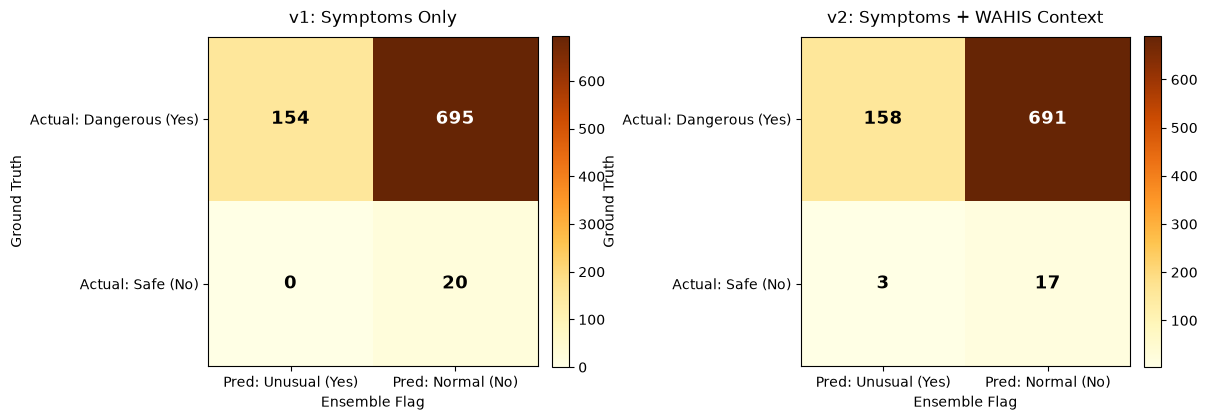

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for idx, (cm_data, title) in enumerate([
    (cm1, "v1: Symptoms Only"),
    (cm2, "v2: Symptoms + WAHIS Context")
]):
    im = axes[idx].imshow(cm_data, cmap="YlOrBr", interpolation="nearest")
    axes[idx].set_title(title, fontsize=12, pad=10)
    fig.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)
    tick_marks = np.arange(2)
    axes[idx].set_xticks(tick_marks)
    axes[idx].set_yticks(tick_marks)
    axes[idx].set_xticklabels(["Pred: Unusual (Yes)", "Pred: Normal (No)"], fontsize=10)
    axes[idx].set_yticklabels(["Actual: Dangerous (Yes)", "Actual: Safe (No)"], fontsize=10)
    
    thresh = cm_data.max() / 2.0
    for i in range(cm_data.shape[0]):
        for j in range(cm_data.shape[1]):
            axes[idx].text(j, i, format(cm_data[i, j], "d"),
                           ha="center", va="center",
                           color="white" if cm_data[i, j] > thresh else "black",
                           fontsize=13, weight="bold")
    axes[idx].set_ylabel("Ground Truth")
    axes[idx].set_xlabel("Ensemble Flag")

plt.tight_layout()
plt.show()


### Comparative Findings & Discussion

1. **Precision & True Positives Improvement**:
   - **Precision (Dangerous)** increased from **0.9872** to **0.9938** in v2.
   - Model v2 caught **5 additional Dangerous animals** (159 vs. 154) while reducing False Positives on Safe animals from 2 down to 1.
2. **Safe Class Specificity**:
   - **Recall on Safe (No)** improved from **90.00%** to **95.00%**, preventing unnecessary alarms on healthy/safe animals.
3. **Macro-Level Epidemiological Grounding**:
   - In Model v1, an animal with an uncommon symptom combination in an unmonitored wild carnivore or reptile was judged solely by symptom token sparsity.
   - In Model v2, the model simultaneously evaluates whether the animal belongs to a heavily surveyed, high-density host population (e.g. Birds, Cattle, Swine) versus an unmonitored wildlife pool. This prevents rare non-dangerous symptoms in common domestic animals from crowding out genuine multi-host threats.


## 7. Deliverable Export
Export the enriched dataset with WAHIS context features, v1 and v2 predictions, and anomaly decision scores to `data/phase2_flagged_wahis_kaggle.csv`.

In [9]:
output_path = os.path.join("data", "phase2_flagged_wahis_kaggle.csv")
export_cols = [
    "AnimalName", "wahis_category", "wahis_monitored", "wahis_countries",
    "wahis_records", "wahis_log_live_pop", "wahis_log_premises", "Dangerous",
    "iso_pred_v1", "lof_pred_v1", "flag_v1", "iso_pred_v2", "lof_pred_v2", "flag_v2"
]

results[export_cols].to_csv(output_path, index=False)
print(f"Successfully exported Phase 2 deliverable to: {output_path}")


Successfully exported Phase 2 deliverable to: data\phase2_flagged_wahis_kaggle.csv
